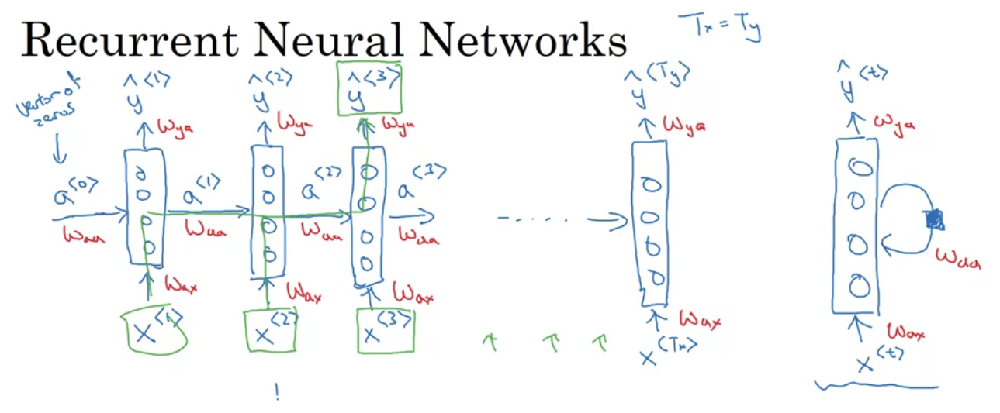

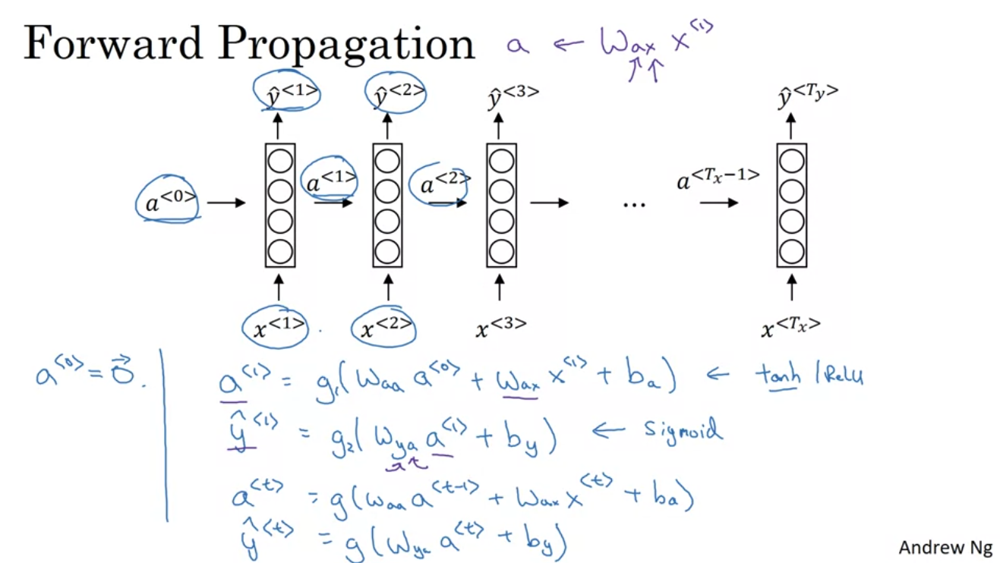

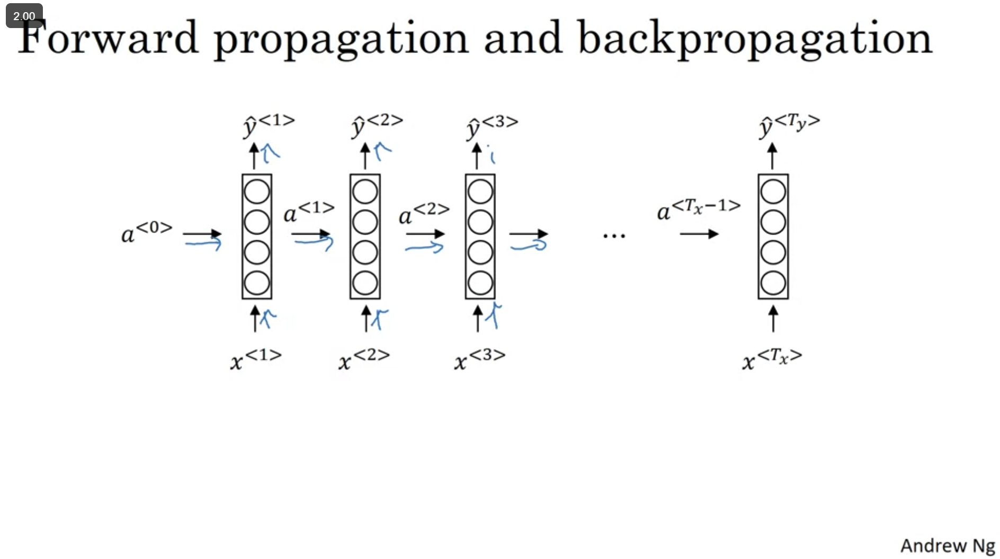

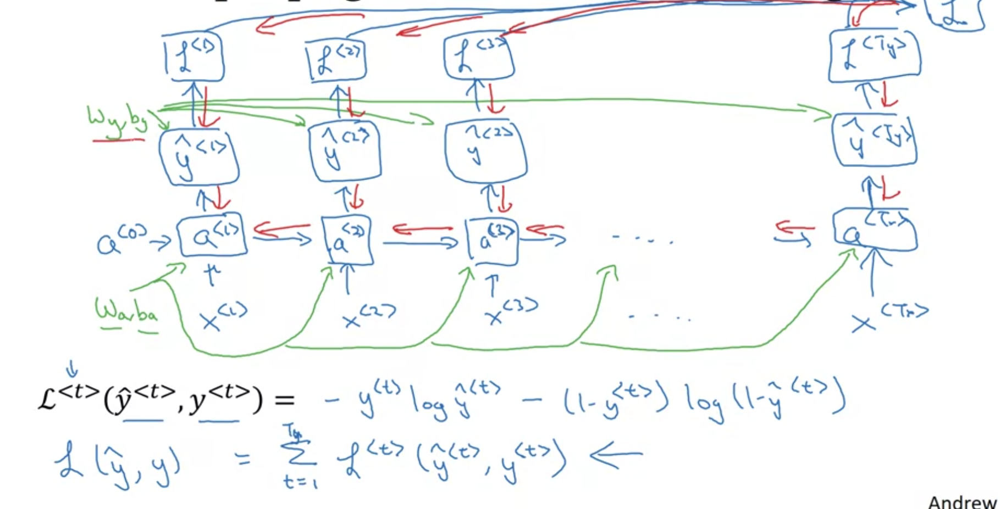

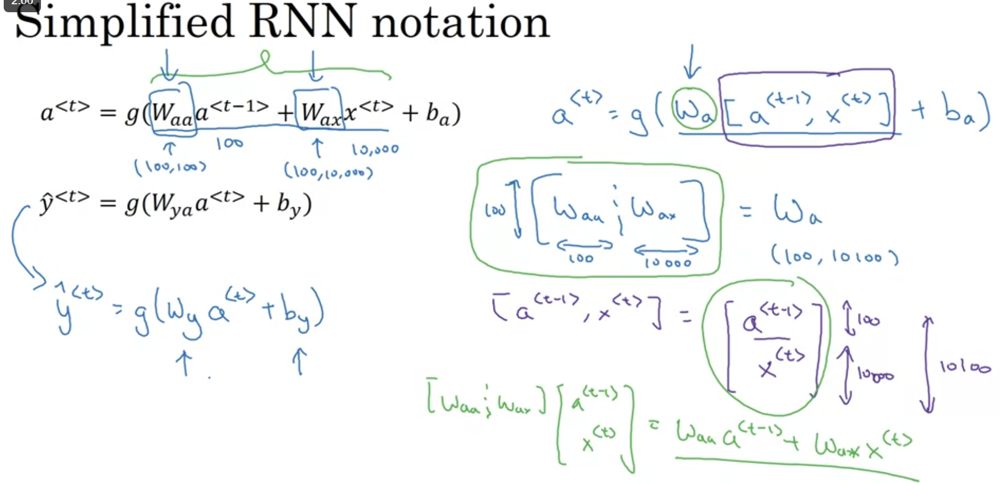

# different Types

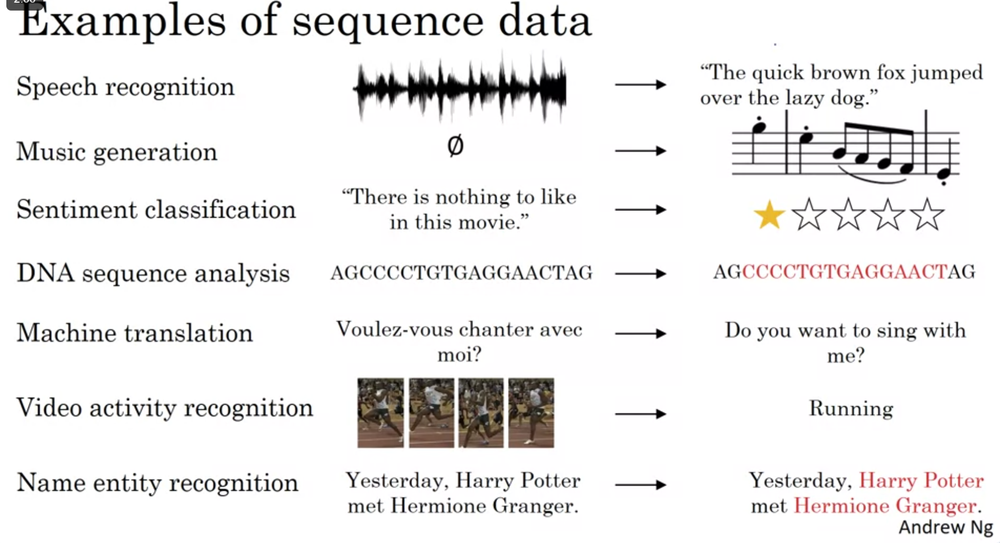

Written as a class, the RNN’s API consists of a single step function:

rnn = RNN()
y = rnn.step(x) # x is an input vector, y is the RNN's output vector
The RNN class has some internal state that it gets to update every time step is called. In the simplest case this state consists of a single hidden vector h. Here is an implementation of the step function in a Vanilla RNN:
```python
class RNN:
  # ...
  def step(self, x):
    # update the hidden state
    self.h = np.tanh(np.dot(self.W_hh, self.h) + np.dot(self.W_xh, x))
    # compute the output vector
    y = np.dot(self.W_hy, self.h)
    return y
```
The above specifies the forward pass of a vanilla RNN. This RNN’s parameters are the three matrices $W_hh$, $W_xh$, $W_hy$. The hidden state self.h is initialized with the zero vector. The np.tanh function implements a non-linearity that squashes the activations to the range [-1, 1]. Notice briefly how this works: There are two terms inside of the tanh: one is based on the previous hidden state and one is based on the current input. In numpy np.dot is matrix multiplication. The two intermediates interact with addition, and then get squashed by the tanh into the new state vector. If you’re more comfortable with math notation, we can also write the hidden state update as $h_t=\tanh(W_{hh}h_{t−1}+W_{xh}x_t)$, where $\tanh$ is applied elementwise.

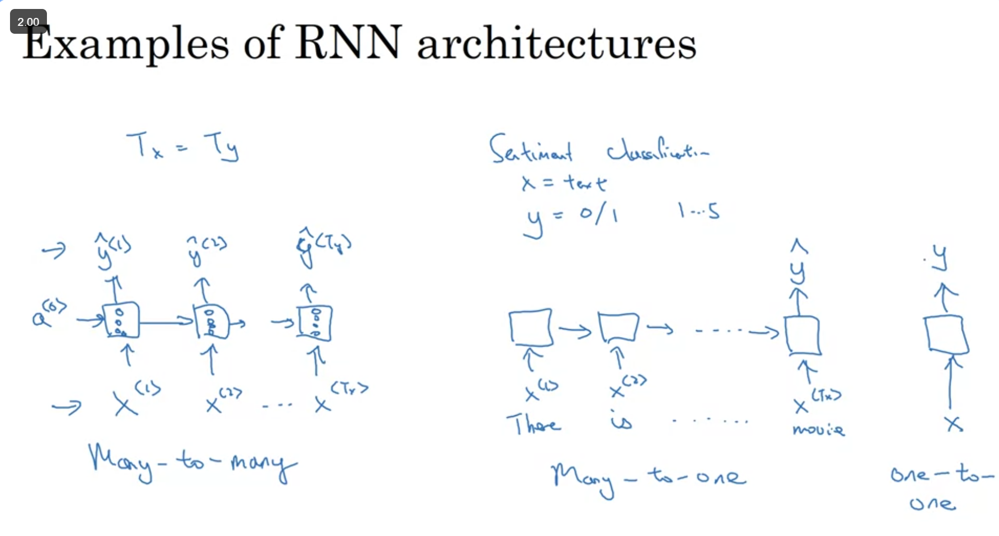

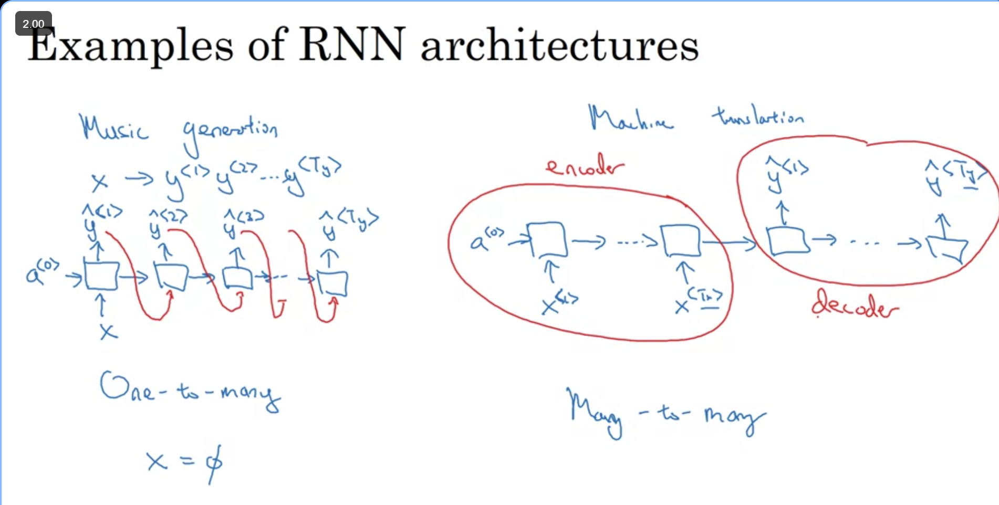

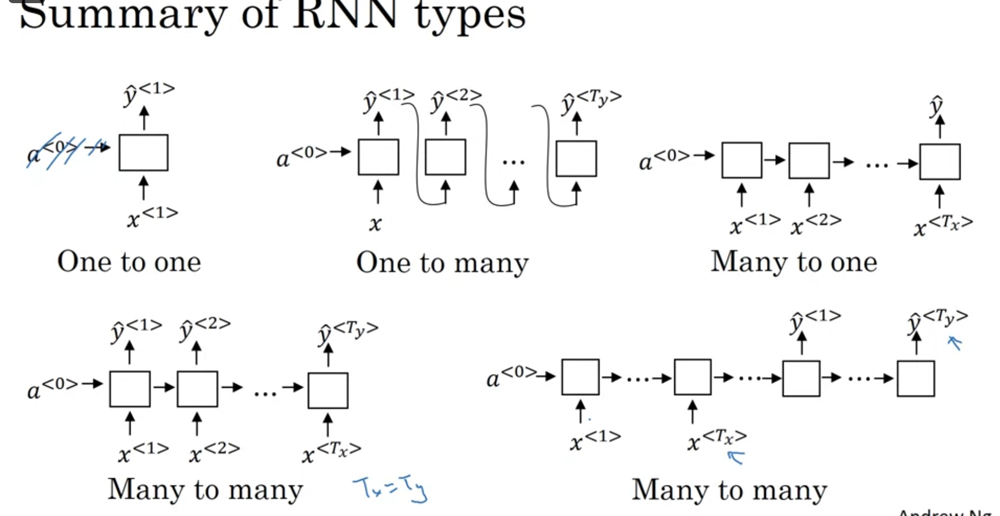

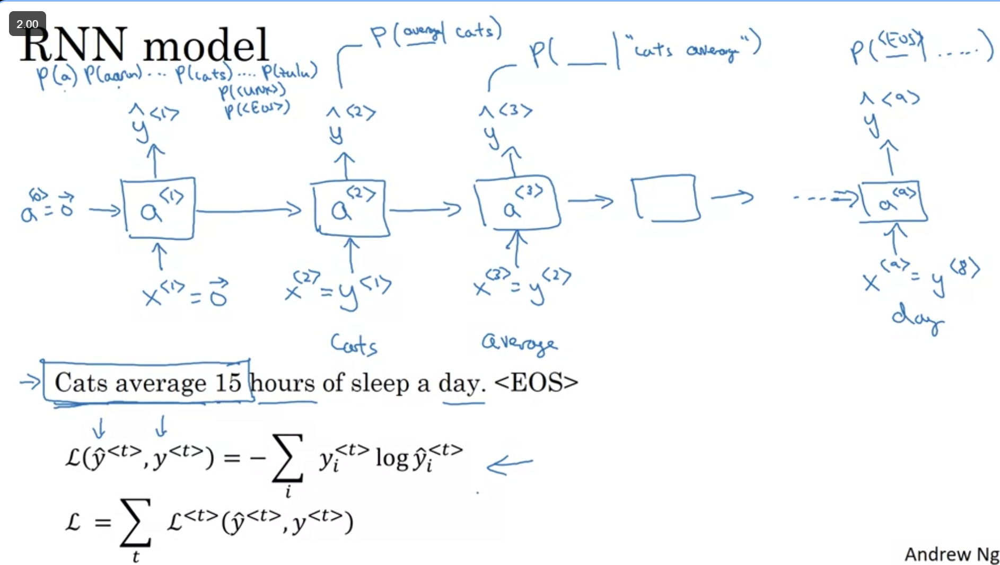

# GRU
## Gated Recurrent Unit (GRU)

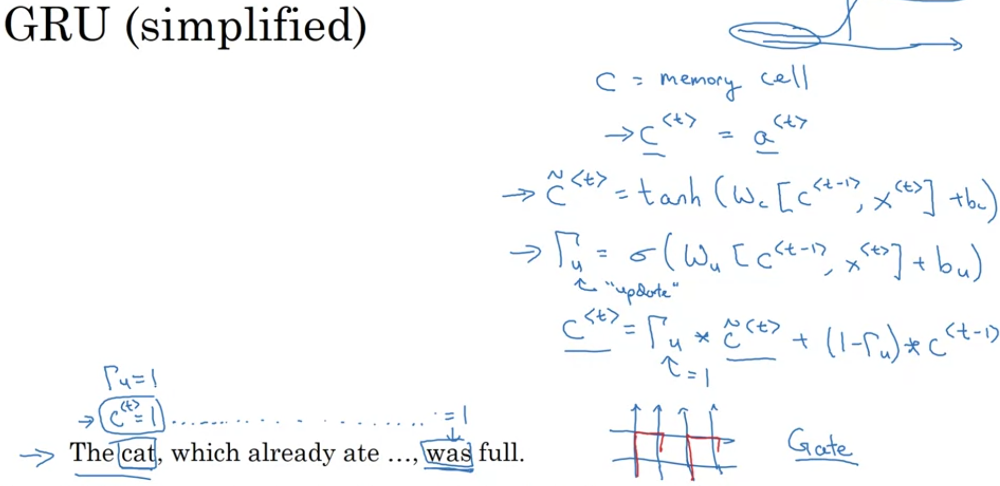

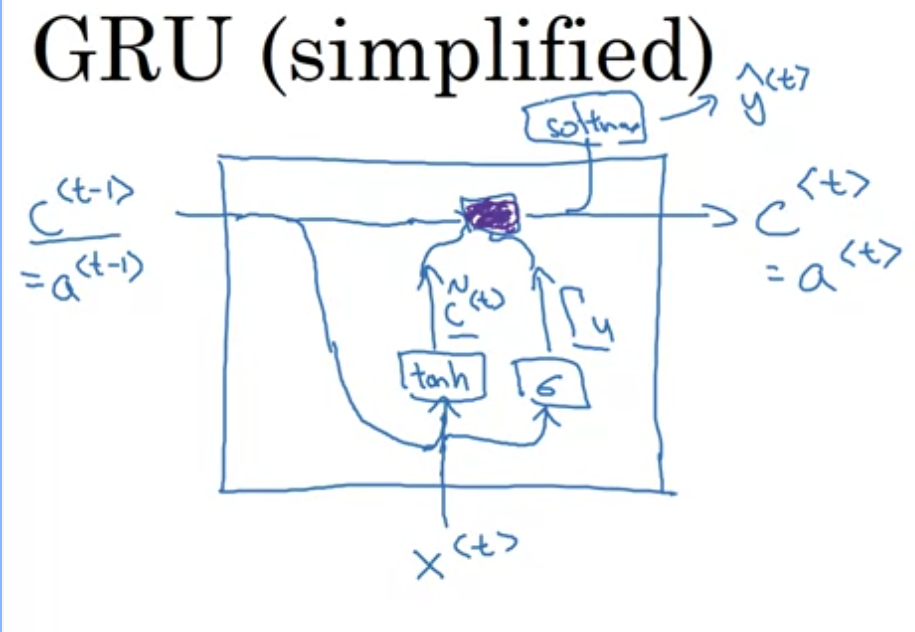

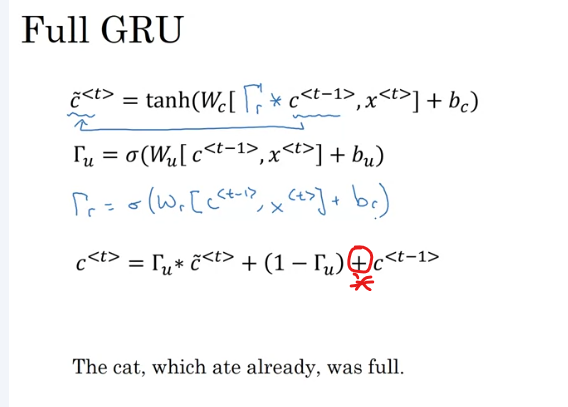

# LSTM
## Long Short-Term Memory (LSTM)

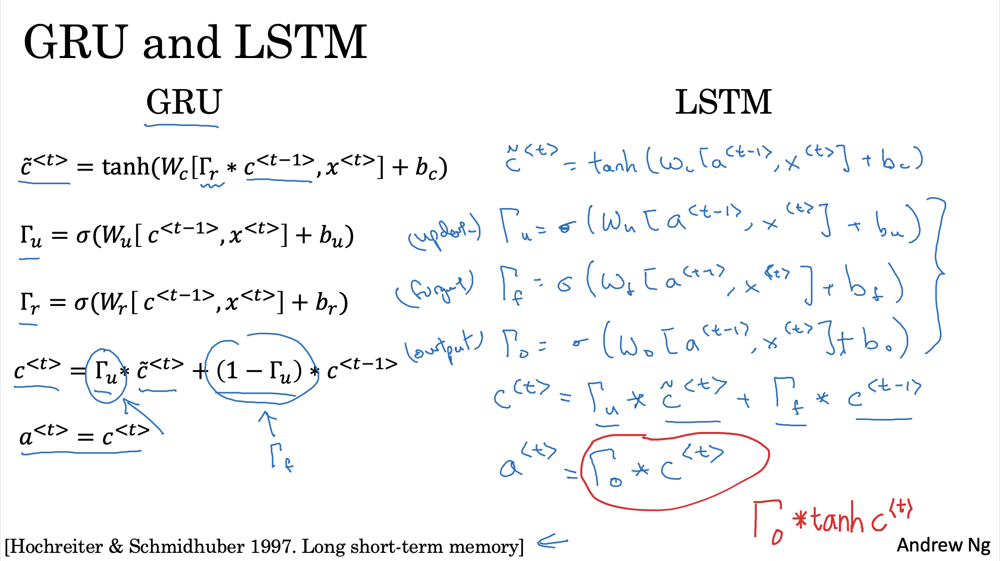

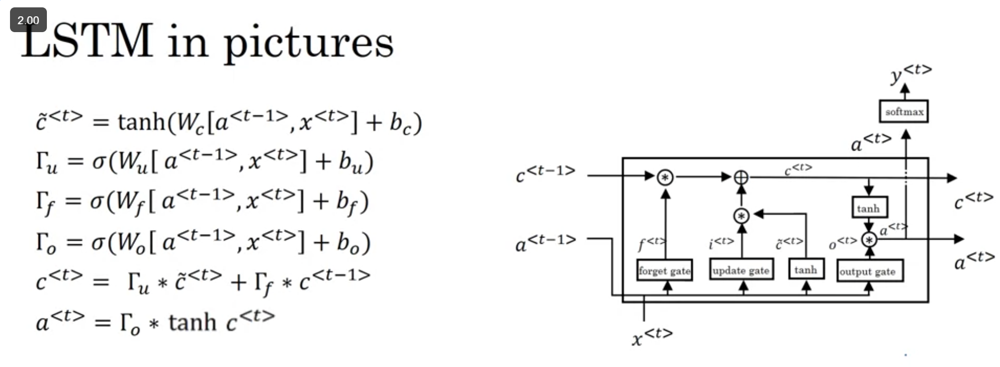

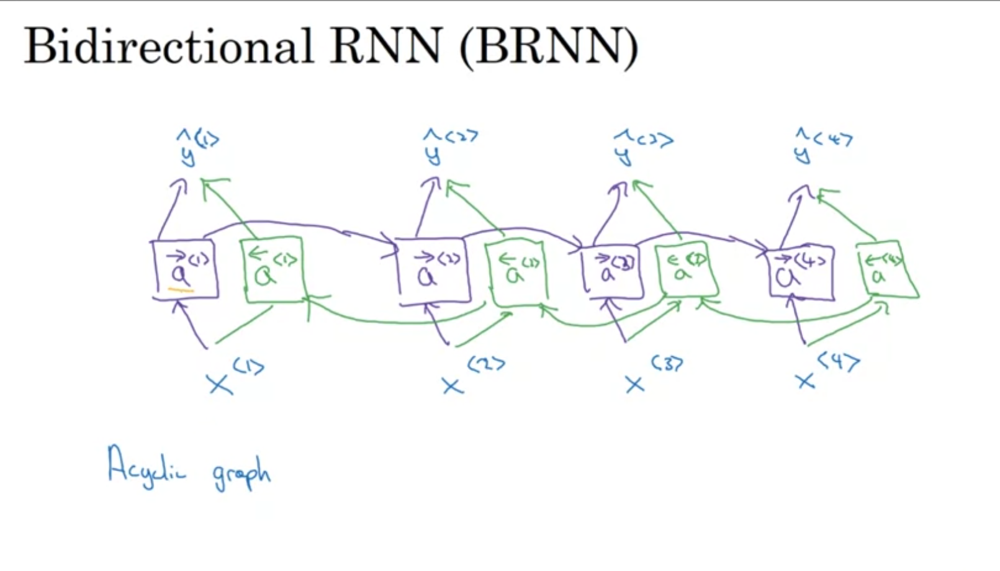

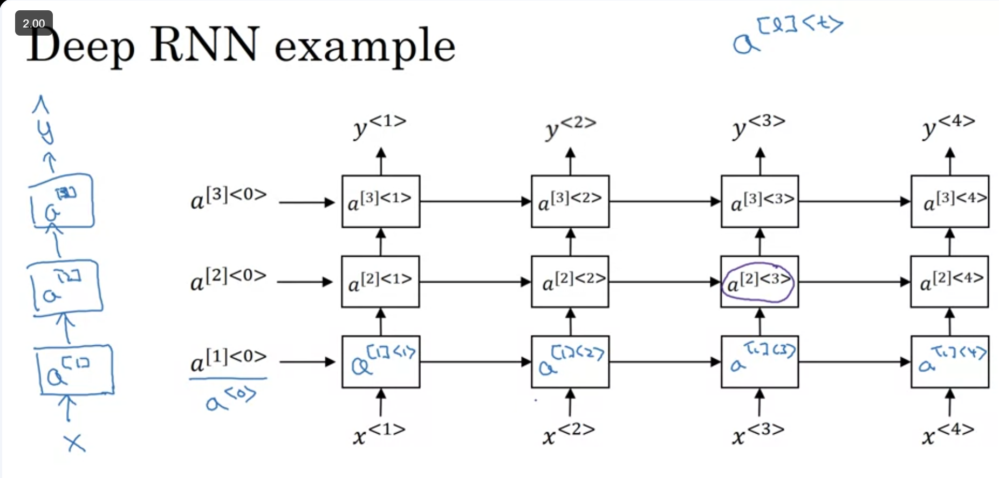

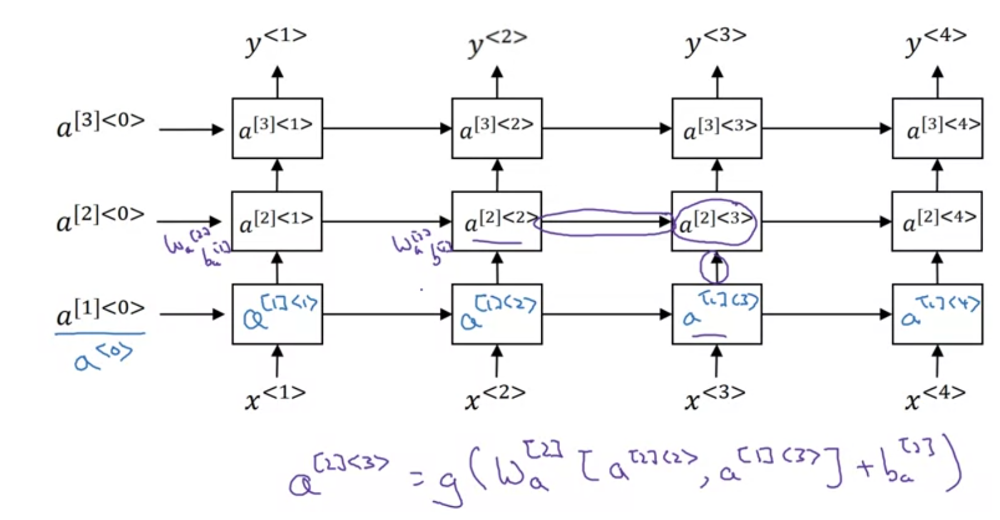

In [1]:
import torch

In [2]:
torch.nn.LSTM?

Init signature: torch.nn.LSTM(*args, **kwargs)
Docstring:     
__init__(input_size,hidden_size,num_layers=1,bias=True,batch_first=False,dropout=0.0,bidirectional=False,proj_size=0,device=None,dtype=None)

Apply a multi-layer long short-term memory (LSTM) RNN to an input sequence.
For each element in the input sequence, each layer computes the following
function:

.. math::
    \begin{array}{ll} \\
        i_t = \sigma(W_{ii} x_t + b_{ii} + W_{hi} h_{t-1} + b_{hi}) \\
        f_t = \sigma(W_{if} x_t + b_{if} + W_{hf} h_{t-1} + b_{hf}) \\
        g_t = \tanh(W_{ig} x_t + b_{ig} + W_{hg} h_{t-1} + b_{hg}) \\
        o_t = \sigma(W_{io} x_t + b_{io} + W_{ho} h_{t-1} + b_{ho}) \\
        c_t = f_t \odot c_{t-1} + i_t \odot g_t \\
        h_t = o_t \odot \tanh(c_t) \\
    \end{array}

where :math:`h_t` is the hidden state at time `t`, :math:`c_t` is the cell
state at time `t`, :math:`x_t` is the input at time `t`, :math:`h_{t-1}`
is the hidden state of the layer at time `t-1` or the initial 

In [3]:
torch.nn.GRU?

Init signature: torch.nn.GRU(*args, **kwargs)
Docstring:     
__init__(input_size,hidden_size,num_layers=1,bias=True,batch_first=False,dropout=0.0,bidirectional=False,device=None,dtype=None)

Apply a multi-layer gated recurrent unit (GRU) RNN to an input sequence.
For each element in the input sequence, each layer computes the following
function:

.. math::
    \begin{array}{ll}
        r_t = \sigma(W_{ir} x_t + b_{ir} + W_{hr} h_{(t-1)} + b_{hr}) \\
        z_t = \sigma(W_{iz} x_t + b_{iz} + W_{hz} h_{(t-1)} + b_{hz}) \\
        n_t = \tanh(W_{in} x_t + b_{in} + r_t \odot (W_{hn} h_{(t-1)}+ b_{hn})) \\
        h_t = (1 - z_t) \odot n_t + z_t \odot h_{(t-1)}
    \end{array}

where :math:`h_t` is the hidden state at time `t`, :math:`x_t` is the input
at time `t`, :math:`h_{(t-1)}` is the hidden state of the layer
at time `t-1` or the initial hidden state at time `0`, and :math:`r_t`,
:math:`z_t`, :math:`n_t` are the reset, update, and new gates, respectively.
:math:`\sigma` is the sigmo

In [4]:
torch.nn.RNN?

Init signature: torch.nn.RNN(*args, **kwargs)
Docstring:     
__init__(input_size,hidden_size,num_layers=1,nonlinearity='tanh',bias=True,batch_first=False,dropout=0.0,bidirectional=False,device=None,dtype=None)

Apply a multi-layer Elman RNN with :math:`\tanh` or :math:`\text{ReLU}`
non-linearity to an input sequence. For each element in the input sequence,
each layer computes the following function:

.. math::
    h_t = \tanh(x_t W_{ih}^T + b_{ih} + h_{t-1}W_{hh}^T + b_{hh})

where :math:`h_t` is the hidden state at time `t`, :math:`x_t` is
the input at time `t`, and :math:`h_{(t-1)}` is the hidden state of the
previous layer at time `t-1` or the initial hidden state at time `0`.
If :attr:`nonlinearity` is ``'relu'``, then :math:`\text{ReLU}` is used instead of :math:`\tanh`.

.. code-block:: python

    # Efficient implementation equivalent to the following with bidirectional=False
    rnn = nn.RNN(input_size, hidden_size, num_layers)
    params = dict(rnn.named_parameters())
    def

In [ ]:
# LSTM with peephole connections using torch.nn

import torch
import torch.nn as nn

class LSTMPeephole(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(LSTMPeephole, self).__init__()
        self.input_size = input_size                    # Size of the input vector at each time step
        self.hidden_size = hidden_size                  # Size of the hidden state vector at each time step
        self.W_i = nn.Linear(input_size, hidden_size)   # Input gate weight for input
        self.W_f = nn.Linear(input_size, hidden_size)   # Forget gate weight for input
        self.W_o = nn.Linear(input_size, hidden_size)   # Output gate weight for input
        self.W_c = nn.Linear(input_size, hidden_size)   # Cell candidate weight for input
        self.U_i = nn.Linear(hidden_size, hidden_size, bias=False)   # Input gate weight for hidden state
        self.U_f = nn.Linear(hidden_size, hidden_size, bias=False)   # Forget gate weight for hidden state
        self.U_o = nn.Linear(hidden_size, hidden_size, bias=False)   # Output gate weight for hidden state
        self.U_c = nn.Linear(hidden_size, hidden_size, bias=False)   # Cell candidate weight for hidden state
        self.V_i = nn.Linear(hidden_size, hidden_size, bias=False)   # Input gate weight for cell state
        self.V_f = nn.Linear(hidden_size, hidden_size, bias=False)   # Forget gate weight for cell state
        self.V_o = nn.Linear(hidden_size, hidden_size, bias=False)   # Output gate weight for cell state

    def forward(self, x, h_prev, c_prev):
        # the peephole connection is implemented using the V_i, V_f, and V_o matrices that connect the cell state to the gates
        # that is in the code line: i = torch.sigmoid(self.W_i(x) + self.U_i(h_prev) + self.V_i(c_prev)), 
        # the part self.V_i(c_prev) represents the peephole connection from the previous cell state to the input gate
        # similarly, self.V_f(c_prev) represents the peephole connection from the previous cell state to the forget gate
        # and self.V_o(c_prev) represents the peephole connection from the previous cell state to the output gate

        i = torch.sigmoid(self.W_i(x) + self.U_i(h_prev) + self.V_i(c_prev)) # Input gate
        f = torch.sigmoid(self.W_f(x) + self.U_f(h_prev) + self.V_f(c_prev)) # Forget gate
        o = torch.sigmoid(self.W_o(x) + self.U_o(h_prev) + self.V_o(c_prev)) # Output gate # this can either use the c_prev (peephole connection) or the current cell state c
        c_tilde = torch.tanh(self.W_c(x) + self.U_c(h_prev)) # Cell candidate
        c = f * c_prev + i * c_tilde # Cell state update
        # if using the current cell state for the output gate peephole connection, it would be: 
        # o = torch.sigmoid(self.W_o(x) + self.U_o(h_prev) + self.V_o(c))
        h = o * torch.tanh(c) # Hidden state update
        return h, c


# Example usage
input_size = 10
hidden_size = 20
batch_size = 5
seq_len = 7

model = LSTMPeephole(input_size, hidden_size)
h_prev = torch.zeros(batch_size, hidden_size)
c_prev = torch.zeros(batch_size, hidden_size)
x = torch.randn(seq_len, batch_size, input_size)
print(x.shape)
for t in range(seq_len):
    h_prev, c_prev = model(x[t], h_prev, c_prev)
    # print(f"Time step {t}: h_prev = {h_prev}, c_prev = {c_prev}")
    # shapes
    print(f"Time step {t}: h_prev shape = {h_prev.shape}, c_prev shape = {c_prev.shape}")



torch.Size([7, 5, 10])
Time step 0: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 1: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 2: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 3: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 4: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 5: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
Time step 6: h_prev shape = torch.Size([5, 20]), c_prev shape = torch.Size([5, 20])
